In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [2]:
df = sns.load_dataset("penguins")
print(df.shape)
df.head()


(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [4]:
print(df["species"].value_counts(normalize = True).round(3))

missing = df.isna().mean().mul(100).round(1)
missing[missing > 0]

df.isna().sum()

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [5]:
num_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(df[num_features].describe().round(1))
print("\nskośność:", df[num_features].skew().round(2).to_dict())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%              44.4           17.3              197.0       4050.0
75%              48.5           18.7              213.0       4750.0
max              59.6           21.5              231.0       6300.0

skośność: {'bill_length_mm': 0.05, 'bill_depth_mm': -0.14, 'flipper_length_mm': 0.35, 'body_mass_g': 0.47}


In [6]:
print(df.groupby("species")[num_features].mean().round(1), "\n")
print(pd.crosstab(df["island"], df["species"]), "\n")
print(pd.crosstab(df["sex"], df["species"]))

           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie               38.8           18.3              190.0       3700.7
Chinstrap            48.8           18.4              195.8       3733.1
Gentoo               47.5           15.0              217.2       5076.0 

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     124
Dream          56         68       0
Torgersen      52          0       0 

species  Adelie  Chinstrap  Gentoo
sex                               
Female       73         34      58
Male         73         34      61


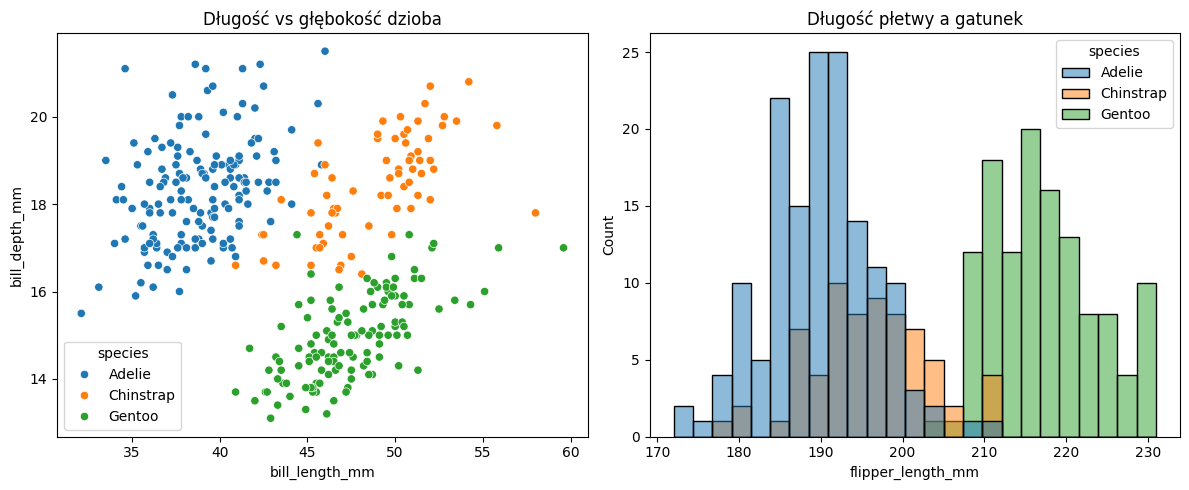

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", ax=axes[0])
axes[0].set_title("Długość vs głębokość dzioba")
sns.histplot(data=df, x="flipper_length_mm", hue="species", bins=25, ax=axes[1])
axes[1].set_title("Długość płetwy a gatunek")
fig.tight_layout()
plt.show()

In [8]:
puste = df[num_features].isna().all(axis=1)
print(df[puste])

df = df[~puste].reset_index(drop=True)
print(df.shape)

#usuwamy wiersze w których brakuje cech, nie zamieniam medianą bo wtedy po imputacji stałyby sztucznymi pingwinami ale z prawdziwą etykietą.

    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
3    Adelie  Torgersen             NaN            NaN                NaN   
339  Gentoo     Biscoe             NaN            NaN                NaN   

     body_mass_g  sex  
3            NaN  NaN  
339          NaN  NaN  
(342, 7)


In [9]:
cat_features = ["island", "sex"]
features = num_features + cat_features
target = "species"

X_train, X_test, y_train, y_test = train_test_split(
    df[features], df[target],
    test_size=0.25,
    stratify=df[target],
    random_state=42,
)
print(X_train.shape, X_test.shape)
print(pd.DataFrame({"train": y_train.value_counts(normalize=True),
                    "test": y_test.value_counts(normalize=True)}).round(3))

(256, 6) (86, 6)
           train   test
species                
Adelie     0.441  0.442
Gentoo     0.359  0.360
Chinstrap  0.199  0.198


In [10]:
przygotowanie = ColumnTransformer([
    ("liczby",    make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_features),
    ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                OneHotEncoder(handle_unknown="ignore")),             cat_features),
])

model = make_pipeline(przygotowanie, LogisticRegression())
model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('liczby',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['bill_length_mm',
                                                   'bill_depth_mm',
                                                   'flipper_length_mm',
                                                   'body_mass_g']),
                                                 ('kategorie',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['island', 'sex'])])),
                ('logisticregression', LogisticRegression())])

In [11]:
model.fit(X_train, y_train)

logreg = model.named_steps["logisticregression"]
nazwy = model.named_steps["columntransformer"].get_feature_names_out()

print("klasy:", logreg.classes_)
print("kształt coef_:", logreg.coef_.shape)   # (3 klasy, liczba cech po transformacji)

# jeden wiersz wag na klasę -> transpozycja dla czytelności
wagi = pd.DataFrame(logreg.coef_, index=logreg.classes_, columns=nazwy)
wagi.T.round(2)

klasy: ['Adelie' 'Chinstrap' 'Gentoo']
kształt coef_: (3, 9)


,Adelie,Chinstrap,Gentoo
liczby__bill_length_mm,-2.24,1.86,0.39
liczby__bill_depth_mm,0.98,0.35,-1.33
liczby__flipper_length_mm,-0.68,-0.27,0.95
liczby__body_mass_g,-0.05,-0.86,0.91
kategorie__island_Biscoe,0.08,-0.70,0.62
kategorie__island_Dream,-0.60,1.08,-0.48
kategorie__island_Torgersen,0.53,-0.38,-0.15
kategorie__sex_Female,-0.57,0.41,0.16
kategorie__sex_Male,0.57,-0.40,-0.16


In [12]:
y_pred = model.predict(X_test)
proba = pd.DataFrame(model.predict_proba(X_test), columns=model.classes_, index=X_test.index)

podglad = X_test.head(5).copy()
podglad = podglad.join(proba.head(5).round(2))
podglad["predykcja"] = y_pred[:5]
podglad["prawda"] = y_test.head(5).values
podglad

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island,sex,Adelie,Chinstrap,Gentoo,predykcja,prawda
52,42.0,19.5,200.0,4050.0,Biscoe,Male,0.99,0.01,0.0,Adelie,Adelie
48,42.3,21.2,191.0,4150.0,Dream,Male,0.97,0.03,0.0,Adelie,Adelie
220,50.0,16.3,230.0,5700.0,Biscoe,Male,0.00,0.00,1.0,Gentoo,Gentoo
316,46.9,14.6,222.0,4875.0,Biscoe,Female,0.00,0.00,1.0,Gentoo,Gentoo
92,39.6,18.1,186.0,4450.0,Dream,Male,0.99,0.01,0.0,Adelie,Adelie


In [13]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

wyniki = pd.Series({
    "baseline (zawsze Adelie)": baseline.score(X_test, y_test),
    "pipeline – train": model.score(X_train, y_train),
    "pipeline – test": model.score(X_test, y_test),
})
wyniki.round(3)

,0
baseline (zawsze Adelie),0.442
pipeline – train,0.996
pipeline – test,1.000


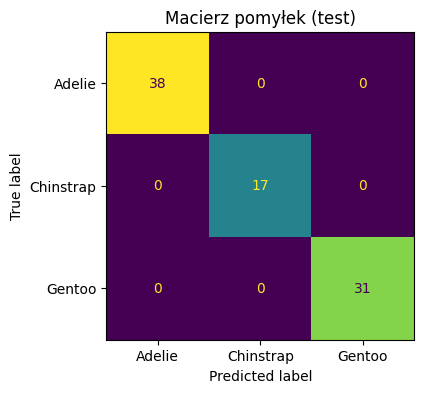

              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        38
   Chinstrap      1.000     1.000     1.000        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          1.000        86
   macro avg      1.000     1.000     1.000        86
weighted avg      1.000     1.000     1.000        86



In [14]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Adelie", "Chinstrap", "Gentoo"]).plot(ax=ax, colorbar=False)
ax.set_title("Macierz pomyłek (test)")
plt.show()

print(classification_report(y_test, y_pred, target_names=["Adelie", "Chinstrap", "Gentoo"], digits=3))

In [15]:
def zbuduj(num, cat):
    przyg = ColumnTransformer([
        ("liczby", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                    OneHotEncoder(handle_unknown="ignore")), cat),
    ])
    return make_pipeline(przyg, LogisticRegression())


warianty = {
    "pełny": zbuduj(num_features, cat_features),
    "bez kategorii": zbuduj(num_features, []),
    "tylko dziób": zbuduj(["bill_length_mm", "bill_depth_mm"], []),
    "tylko masa": zbuduj(["body_mass_g"], []),
}
pd.Series({nazwa: m.fit(X_train,y_train).score(X_test, y_test) for nazwa, m in warianty.items()}).round(3)

,0
pełny,1.000
bez kategorii,1.000
tylko dziób,0.965
tylko masa,0.767
